# Nieve y hielo visible en el Nevado Santa Isabel · entrenamiento, evaluación y paquete

**Pregunta.** ¿Cuánta cobertura de nieve y hielo visible hay en una escena Sentinel-2 del Santa Isabel y dónde
cambió entre dos fechas?

**Objetivo del cuaderno.** Afinar un modelo de segmentación de instancias (YOLO26n-seg) con el dataset mensual
del generador (SDD 03), elegir checkpoint, resolución y umbral **solo con validación**, aplicar esa configuración
congelada **una vez** a la prueba temporal y publicar un paquete inmutable que la aplicación Streamlit consume con
las mismas funciones de lectura, inferencia y medición (`src/santa_isabel`).

**Alcance.** La clase reúne nieve e hielo visibles. Las etiquetas son pseudoetiquetas automáticas por reglas NDSI,
sin revisión humana: las métricas miden *concordancia con esas pseudoetiquetas*. Dos fechas no miden balance de
masa ni permiten atribuir una tendencia glaciar; en la interfaz y en el informe se habla de **pérdida observada de
cobertura**.

Kernel: **Python (yolo_gee)**. Cada bloque guarda sus tablas y figuras en `reports/<run_id>/`.

## 1 · Configuración, dispositivo y estado de preparación

In [1]:
import santa_isabel  # primero: fija PROJ/GDAL y la capa de hilos de MKL antes de importar numpy

import json, os, subprocess, sys, time
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from santa_isabel import areas, cargar_config, cuaderno, dataset, flujo, paquete, visual
from santa_isabel import entrenamiento as ent
from santa_isabel.escenas import leer_escena

pd.set_option("display.width", 220, "display.max_columns", 40, "display.float_format", "{:.4f}".format)

VARIANTE = "rgb"                                  # primero RGB; el experimento espectral es posterior
PRUEBA_RAPIDA = os.environ.get("SI_SMOKE") == "1"  # ensayo de integración del cuaderno (no publica en models/)
cfg = cargar_config()                              # resuelve la raíz del proyecto, no el directorio de Jupyter
RAIZ = Path(cfg["_raiz"])
RUN_ID = os.environ.get("SI_RUN_ID") or (("smoke_" if PRUEBA_RAPIDA else "") +
                                         f"{VARIANTE}_{cfg['dataset']['version']}_{datetime.now():%Y%m%d_%H%M}")
CORRIDA = RAIZ / "runs" / RUN_ID
REPORTES = CORRIDA / "reports" if PRUEBA_RAPIDA else RAIZ / "reports" / RUN_ID
MODELOS = CORRIDA / "models" if PRUEBA_RAPIDA else RAIZ / "models"
EJEMPLOS = CORRIDA / "examples" if PRUEBA_RAPIDA else RAIZ / "examples"
for carpeta in (CORRIDA, REPORTES, MODELOS):
    carpeta.mkdir(parents=True, exist_ok=True)

gpu = ent.diagnostico_gpu(exigir=True)   # se detiene con diagnóstico de kernel, wheel y driver si no hay CUDA
print("Intérprete :", sys.executable)
print(f"torch {gpu['torch']} · torchvision {gpu['torchvision']} · ultralytics {gpu['ultralytics']} · CUDA "
      f"{gpu['cuda_compilada']} · cuDNN {gpu['cudnn']}")
print(f"GPU        : {gpu['gpu']} · VRAM {gpu['vram_total_mib']} MiB (libre {gpu['vram_libre_mib']} MiB) · "
      f"operación tensorial en {gpu['operacion_cuda']} sincronizada: {gpu['operacion_ok']}")
e, inf = cfg["entrenamiento"], cfg["inferencia"]
print(f"Dataset    : {cfg['dataset']['version']} · variante {VARIANTE} · {dataset.carpeta_version(cfg)}")
print(f"Caché QA   : {dataset.raiz_cache(cfg) or 'no configurada (métricas sobre toda la imagen)'}")
print(f"Semilla {cfg['proyecto']['semilla']} · device={e['device']} · workers={e['workers']} · lote {e['lote']} · "
      f"imgsz {e['imgsz']} · modelo base {e['modelo_base']}")
print(f"Corrida    : {RUN_ID}\n  runs    → {CORRIDA}\n  reports → {REPORTES}\n  models  → {MODELOS}")
SOPORTE = "observable" if dataset.raiz_cache(cfg) else "imagen"
print(f"Soporte de evaluación principal: {flujo.SOPORTES[SOPORTE]}")

Intérprete : C:\Users\ing_c\miniconda3\envs\yolo_gee\python.exe
torch 2.15.0+cu132 · torchvision 0.29.2+cu132 · ultralytics 8.4.216 · CUDA 13.2 · cuDNN 92600
GPU        : NVIDIA GeForce RTX 3050 Laptop GPU · VRAM 4095 MiB (libre 3263 MiB) · operación tensorial en cuda:0 sincronizada: True
Dataset    : v0003 · variante rgb · C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS MAESTRÍA\M-S2-VC Proyecto imagenes satelitales YOLO\santa_isabel_yolo\data\datasets\v0003
Caché QA   : C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS GEE\Selector de imágen satelital\dataset_mensual_yolo\salida\cache_escenas
Semilla 42 · device=0 · workers=0 · lote 2 · imgsz 1024 · modelo base yolo26n-seg.pt
Corrida    : rgb_v0003_20261122_2200
  runs    → C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS MAESTRÍA\M-S2-VC Proyecto imagenes satelitales YOLO\santa_isabel_yolo\runs\rgb_v0003_20261122_2200
  reports → C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS MAESTRÍA\M-S2-VC Proyecto imagenes satelitales YOLO\santa_isabe

## 2 · Auditoría y exploración

Antes de entrenar se valida el contrato con el generador: archivos, encabezados, claves, fechas UTC, perfil
L1C/L2A, hashes, clase única, pares imagen–etiqueta en ambas variantes y ausencia de fuga de fechas entre splits.
Un archivo corrupto, un TXT ausente o una fecha duplicada **bloquean** el entrenamiento. Los splits son los del
generador (92/19/21 meses planificados); abajo se ven las escenas útiles reales.

In [2]:
aud = dataset.auditar_dataset(cfg)
tabla_splits = pd.DataFrame(aud.tabla_splits())
display(tabla_splits)
for aviso in aud.avisos:
    print("AVISO  ·", aviso)
if not aud.ok:
    raise RuntimeError("La auditoría bloquea el entrenamiento:\n- " + "\n- ".join(aud.bloqueos))
identidad = aud.identidad()
print(f"\nAuditoría superada: {len(aud.filas)} escenas, {len(aud.instancias)} instancias, "
      f"{aud.hashes_verificados} hashes verificados contra el manifiesto.")
print("Límites temporales (cortes del generador):", aud.resumen["cortes"]["corte_val"], "→ val ·",
      aud.resumen["cortes"]["corte_test"], "→ test · huella de contenido", identidad["huella_contenido"])
cuaderno.guardar_csv(aud.tabla_splits(), REPORTES / "tabla_splits.csv")
cuaderno.guardar_json({"identidad": identidad, "avisos": aud.avisos, "meses": aud.meses,
                       "equivalencias_manifiesto": dataset.EQUIVALENCIAS}, REPORTES / "auditoria.json");

,split,meses_planificados,escenas,positivas,negativas,instancias,L1C,L2A,años,meses_ausentes,revision_humana
0,train,92,18,18,0,273,9,9,"2016, 2017, 2018, 2020, 2021, 2022, 2023",74,0
1,val,19,4,4,0,7,0,4,"2024, 2025",15,0
2,test,21,6,6,0,41,0,6,"2025, 2026",15,0


AVISO  · Soporte de validación pequeño: 4 escena(s) y 7 instancia(s); la selección de checkpoint y umbral es inestable.
AVISO  · No hay escenas totalmente negativas: no se mide el comportamiento sin nieve.
AVISO  · Ninguna escena tiene revisión humana registrada: la referencia es automática (automatico_ndsi); las métricas son concordancia con pseudoetiquetas.
AVISO  · Configuración efectiva del productor: ambiguos_bloquean = false. Los componentes NDSI ambiguos (p. ej. en contacto con nubes) quedan como fondo en las etiquetas sin bloquear la escena.
AVISO  · Aviso del productor: Pseudoetiquetas automáticas por reglas NDSI sin revisión humana; no son verificación glaciológica.

Auditoría superada: 28 escenas, 321 instancias, 112 hashes verificados contra el manifiesto.
Límites temporales (cortes del generador): 2023-09 → val · 2025-04 → test · huella de contenido ef44e9dcf906fd08


**Tamaño de los parches.** La red ve la imagen reescalada a `imgsz` y, al entrenar, compara máscaras reducidas por
`mask_ratio`. Un parche que ocupa menos de una celda de esa máscara apenas aporta señal: la tabla cuenta cuántos
hay para cada resolución candidata (1 px = 10 m × 10 m = 0,01 ha).

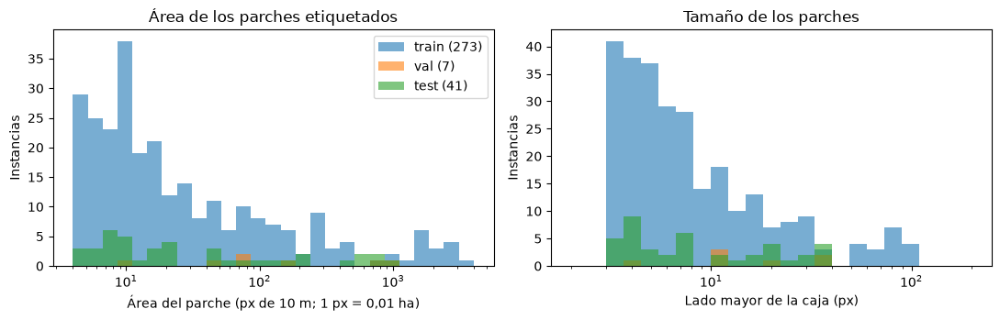

,imgsz,escala,mask_ratio,lado_mascara_px,celda_de_mascara_en_px_originales,parche_minimo_px,parche_minimo_en_celdas,instancias_bajo_1_celda,instancias_bajo_4_celdas,instancias
0,640,1.0700,4,160,3.7400,5.0000,0.3600,145,230,321
1,1024,1.7120,4,256,2.3400,5.0000,0.9200,32,184,321
2,1280,2.1400,4,320,1.8700,5.0000,1.4300,0,145,321


In [3]:
cuaderno.figura_histogramas(aud, REPORTES / "fig_histogramas.png"); plt.show()
tabla_tam = pd.DataFrame(cuaderno.tabla_tamano_minimo(aud, cfg, inf["imgsz_candidatos"], e["mask_ratio"]))
display(tabla_tam)
tabla_tam.to_csv(REPORTES / "tabla_tamano_minimo.csv", index=False, encoding="utf-8-sig")

## 3 · Referencias

Los polígonos YOLO (bordes de píxel, normalizados) se rasterizan a la malla del PNG con la regla del productor:
un píxel es positivo si su centro cae dentro del polígono. Con la caché del generador se cruza cada escena con su
máscara de calidad (`calidad.tif = 2`: observado y visible) y su soporte. Se prepara también el comparador
**NDSI ≥ umbral** con la receta del productor.

> **Circularidad.** La pseudoetiqueta nace del NDSI. Evaluar el umbral NDSI contra ella es circular y no demuestra
> superioridad de ningún método. Además, la configuración efectiva del productor (`ambiguos_bloquean = false`) deja
> como **fondo** los componentes NDSI ambiguos (p. ej. en contacto con nubes): la columna `ambiguos_ha` muestra
> cuánta superficie queda en esa situación. Por eso se reporta también una evaluación que excluye esos píxeles.

,split,mes,fecha_utc,perfil,instancias,referencia_ha,cache,observable_pct,referencia_no_observable_ha,ambiguos_ha,componentes_ambiguos,ndsi_umbral_ha,ndsi_umbral_observable_ha
0,train,2016-01,2016-01-30T15:31:09Z,L1C,20,94.5900,True,100.0000,0.0000,5.0300,24,99.5800,99.5800
1,train,2016-07,2016-07-08T15:30:15Z,L1C,7,2.7600,True,100.0000,0.0000,137.0100,31,137.9900,137.9900
2,train,2016-09,2016-09-16T15:31:08Z,L1C,88,21.0800,True,100.0000,0.0000,1661.7000,271,1632.0800,1632.0800
3,train,2017-04,2017-04-04T15:31:09Z,L1C,14,65.3900,True,99.9000,0.0000,15.7500,14,80.7900,80.7900
4,train,2017-06,2017-06-03T15:31:14Z,L1C,8,41.3800,True,97.6000,0.0000,1.5700,4,42.7600,42.7600
5,train,2018-01,2018-01-24T15:26:32Z,L1C,24,3.7500,True,100.0000,0.0000,278.7200,78,277.1400,277.1400
6,train,2018-02,2018-02-08T15:28:52Z,L1C,10,59.8300,True,98.1000,0.0000,4.0300,7,63.8600,63.8600
7,train,2018-03,2018-03-10T15:26:35Z,L1C,10,57.8400,True,100.0000,0.0000,2.7000,4,60.5400,60.5400
8,train,2018-11,2018-11-15T15:31:42Z,L1C,9,6.7900,True,83.1000,0.0000,81.5400,31,87.8200,87.7500
9,train,2018-12,2018-12-15T15:31:39Z,L2A,8,4.0200,True,89.0000,0.0000,74.1000,41,77.9800,76.0100


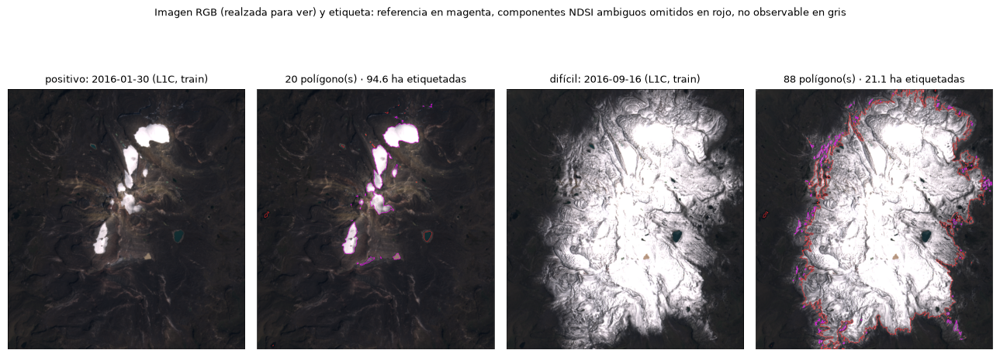

Ejemplo negativo: no existe en v0003 (las 28 escenas son positivas).
Delineación humana independiente: ninguna escena del dataset la tiene (revision_humana = False en todas). La revisión de la escena piloto 2024-01-23 del selector fue asistida por NDSI: sirve para integración, no como prueba independiente.


In [4]:
tabla_ref = cuaderno.tabla_referencias(aud, cfg)
display(pd.DataFrame(tabla_ref).drop(columns=["origen", "revision_humana"]))
cuaderno.guardar_csv(tabla_ref, REPORTES / "tabla_referencias.csv")
ejemplos_etiqueta = cuaderno.elegir_ejemplos(tabla_ref)
cuaderno.figura_ejemplos(aud, cfg, {"positivo": ejemplos_etiqueta["positivo"], "difícil": ejemplos_etiqueta["dificil"]},
                         REPORTES / "fig_ejemplos_etiquetas.png"); plt.show()
print("Ejemplo negativo: no existe en", aud.version, "(las", len(aud.filas), "escenas son positivas).")
print("Delineación humana independiente: ninguna escena del dataset la tiene (revision_humana = False en todas).",
      "La revisión de la escena piloto 2024-01-23 del selector fue asistida por NDSI: sirve para integración, no",
      "como prueba independiente.")

## 4 · Entrenamiento en la RTX

Se afina `yolo26n-seg.pt` preentrenado con una clase. Cada parche es una instancia; la cobertura es la **unión** de
las máscaras. Los `data.yaml` del generador traen un `path:` absoluto de otro equipo: se generan copias locales en
la carpeta de corrida cambiando solo esa línea. Sin mosaic, mixup ni jitter HSV (alterarían el significado
radiométrico); solo aumentos geométricos, que transforman igual imagen y polígonos.

Tres pasos: (a) un lote real y una época de integración con el pico de memoria; (b) la **configuración inicial
propuesta** (hasta 50 épocas, paciencia 10); (c) la **corrida ajustada** que resulta de medir (b).

YAML local: C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS MAESTRÍA\M-S2-VC Proyecto imagenes satelitales YOLO\santa_isabel_yolo\runs\rgb_v0003_20261122_2200\data_yaml\v0003_rgb.yaml
# Dataset YOLO Segmentation · variante rgb · versión v0003
# Pseudoetiquetas automáticas (NDSI); no es verificación glaciológica.
# Si mueves la carpeta: python -m mensual --regenerar-yaml <carpeta_version>
path: "C:/Users/ing_c/OneDrive/Documentos/DESARROLLOS MAESTRÍA/M-S2-VC Proyecto imagenes satelitales YOLO/santa_isabel_yolo/data/datasets/v0003/rgb"
train: images/train
val: images/val
test: images/test
names:
  0: nieve_hielo_visible

val: Fast image access  (ping: 0.1±0.0 ms, read: 2241.5±195.6 MB/s, size: 416.2 KB)


val: Scanning C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS MAESTRÍA\M-S2-VC Proyecto imagenes satelitales YOLO\santa_isabel_yolo\data\datasets\v0003\rgb\labels\train.cache... 18 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 18/18  0.0s

val: Fast image access  (ping: 0.1±0.0 ms, read: 1640.0±295.9 MB/s, size: 437.8 KB)


val: Scanning C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS MAESTRÍA\M-S2-VC Proyecto imagenes satelitales YOLO\santa_isabel_yolo\data\datasets\v0003\rgb\labels\val.cache... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4  0.0s

val: Fast image access  (ping: 0.1±0.0 ms, read: 2524.8±88.7 MB/s, size: 441.8 KB)


val: Scanning C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS MAESTRÍA\M-S2-VC Proyecto imagenes satelitales YOLO\santa_isabel_yolo\data\datasets\v0003\rgb\labels\test.cache... 6 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 6/6  0.0s

,split,imagenes,instancias,lote_img,lote_masks,dtype_img,instancias_en_lote
0,train,18,273,"[2, 3, 1024, 1024]","[2, 256, 256]",torch.uint8,27
1,val,4,7,"[2, 3, 1024, 1024]","[2, 256, 256]",torch.uint8,2
2,test,6,41,"[2, 3, 1024, 1024]","[2, 256, 256]",torch.uint8,29


,nombre,dispositivo,gpu,epocas_pedidas,epocas_ejecutadas,mejor_epoca_fitness,segundos,pico_asignado_mib,pico_reservado_mib,nbs,paciencia
0,1_integracion,cuda:0,NVIDIA GeForce RTX 3050 Laptop GPU,1,1,1,20.9000,1752,2170,64,10
1,2_inicial,cuda:0,NVIDIA GeForce RTX 3050 Laptop GPU,50,12,2,57.6000,2001,2498,64,10
2,3_ajustada,cuda:0,NVIDIA GeForce RTX 3050 Laptop GPU,150,150,91,574.4000,1998,2550,2,0


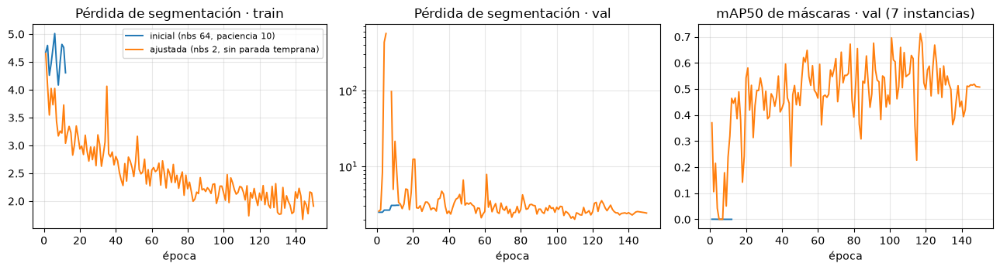

In [5]:
yamls = dataset.yaml_locales(cfg, CORRIDA)
print("YAML local:", yamls[VARIANTE]); print(yamls[VARIANTE].read_text(encoding="utf-8"))
display(pd.DataFrame([ent.comprobar_lote(cfg, yamls[VARIANTE], s) for s in dataset.SPLITS]))
aj = e["ajustado"]
reg_int = ent.entrenar(cfg, yamls[VARIANTE], CORRIDA, "1_integracion", epocas=e["epocas_integracion"], silencioso=True)
reg_ini = ent.entrenar(cfg, yamls[VARIANTE], CORRIDA, "2_inicial", epocas=2 if PRUEBA_RAPIDA else e["epocas"],
                       silencioso=True)
reg_aj = ent.entrenar(cfg, yamls[VARIANTE], CORRIDA, "3_ajustada", epocas=3 if PRUEBA_RAPIDA else aj["epocas"],
                      paciencia=aj["paciencia"], silencioso=True,
                      extra={"nbs": aj["nbs"], "save_period": 1 if PRUEBA_RAPIDA else aj["guardar_cada"]})
registros = pd.DataFrame([{k: r[k] for k in ("nombre", "dispositivo", "gpu", "epocas_pedidas", "epocas_ejecutadas",
                                             "mejor_epoca_fitness", "segundos", "pico_asignado_mib",
                                             "pico_reservado_mib")} | {"nbs": r["argumentos"].get("nbs"),
                                                                       "paciencia": r["argumentos"].get("patience")}
                          for r in (reg_int, reg_ini, reg_aj)])
display(registros)
registros.to_csv(REPORTES / "tabla_entrenamiento.csv", index=False, encoding="utf-8-sig")
cuaderno.guardar_json({"integracion": reg_int, "inicial": reg_ini, "ajustada": reg_aj}, REPORTES / "entrenamiento.json")
cuaderno.figura_curvas({"inicial (nbs 64, paciencia 10)": reg_ini["carpeta"],
                        f"ajustada (nbs {aj['nbs']}, sin parada temprana)": reg_aj["carpeta"]},
                       REPORTES / "fig_curvas_entrenamiento.png"); plt.show()

**Lectura.** Con lote 2, Ultralytics acumula gradientes hasta un lote nominal `nbs = 64`: 32 lotes por paso del
optimizador, es decir un paso cada ~3,5 épocas con 9 lotes por época. Además, la parada temprana usa el mAP de
instancia de validación (4 escenas, 7 instancias), que es ruido. Por eso la corrida inicial se detiene pronto sin
haber aprendido. La corrida ajustada usa `nbs = lote` (un paso por lote), desactiva la parada temprana y guarda
checkpoints periódicos. `best.pt` responde al *fitness* interno de Ultralytics (mAP de cajas y máscaras en
validación); la selección final de este cuaderno usa el IoU de cobertura, en el bloque siguiente.

## 5 · Selección con validación

Solo se usa validación. Para cada checkpoint se hace **una inferencia por imagen** con umbral de propuestas bajo
(0,01) y se guarda la confianza y la máscara de cada instancia. La puntuación de un píxel es el **máximo** de las
confianzas de las instancias que lo cubren (0 fuera de propuestas): un ranking con empates, no una probabilidad
calibrada. Se elige el checkpoint con mayor **IoU de cobertura** (desempate: menor MAE de área), después la
resolución de inferencia y por último el **umbral operativo que maximiza F1** (empates → umbral mayor). La
configuración se congela en un protocolo que impide evaluar test antes o más de una vez.

In [6]:
protocolo = flujo.Protocolo()
pesos = ent.checkpoints_candidatos({"2_inicial": reg_ini["carpeta"], "3_ajustada": reg_aj["carpeta"]},
                                   CORRIDA / "candidatos")
candidatos = []
for c in pesos:
    modelo = paquete.modelo_en_memoria(c["ruta"], cfg, VARIANTE, dispositivo=0)
    el = flujo.inferir_split(cfg, aud, modelo, "val", protocolo=protocolo, proposito="seleccion de checkpoint")
    u = flujo.elegir_umbral(el, SOPORTE)
    candidatos.append({"checkpoint": c["checkpoint"], "ruta": str(c["ruta"]), "imgsz": e["imgsz"],
                       **flujo.resumen_seleccion(el, u["umbral"], SOPORTE),
                       "propuestas": sum(x["instancias_propuestas"] for x in el),
                       "tope_alcanzado": any(x["tope_alcanzado"] for x in el)})
k = flujo.mejor_candidato(candidatos)
tabla_ckpt = pd.DataFrame(candidatos).drop(columns="ruta")
tabla_ckpt["elegido"] = ["◀" if i == k else "" for i in range(len(candidatos))]
display(tabla_ckpt)
tabla_ckpt.to_csv(REPORTES / "seleccion_checkpoints.csv", index=False, encoding="utf-8-sig")
PESOS = Path(candidatos[k]["ruta"])
ious = pd.to_numeric(tabla_ckpt["iou"], errors="coerce").dropna()
IOU_MIN, IOU_MAX = (float(ious.min()), float(ious.max())) if len(ious) else (None, None)
print("Checkpoint elegido por IoU de cobertura en validación:", candidatos[k]["checkpoint"])
print(f"IoU entre los {len(candidatos)} checkpoints: mínimo {IOU_MIN} · máximo {IOU_MAX} "
      f"(con {len(el)} escenas de validación la selección es inestable)")

,checkpoint,imgsz,iou,f1,precision,recall,mae_ha,sesgo_ha,auc,umbral,propuestas,tope_alcanzado,elegido
0,2_inicial/best.pt,1024,0.0507,0.0965,0.0545,0.4205,39.5925,34.5275,0.9170,0.0360,330,False,
1,2_inicial/last.pt,1024,0.0084,0.0166,0.0084,0.8605,523.5550,523.0000,0.8184,0.0398,276,False,
2,3_ajustada/best.pt,1024,0.5606,0.7184,0.5764,0.9533,3.3775,3.3625,0.9779,0.2618,51,False,
3,3_ajustada/last.pt,1024,0.4142,0.5858,0.4728,0.7696,4.8275,3.2275,0.8846,0.0642,44,False,
4,3_ajustada/epoch0.pt,1024,0.4516,0.6222,0.4765,0.8965,5.0875,4.5325,0.9869,0.0352,125,False,
5,3_ajustada/epoch10.pt,1024,0.3471,0.5153,0.5063,0.5246,4.6950,0.1850,0.7774,0.5491,268,False,
6,3_ajustada/epoch20.pt,1024,0.4634,0.6334,0.4924,0.8872,4.8125,4.1225,0.9682,0.2922,173,False,
7,3_ajustada/epoch30.pt,1024,0.5115,0.6768,0.5293,0.9383,4.1025,3.9725,0.9721,0.2677,326,False,
8,3_ajustada/epoch40.pt,1024,0.4437,0.6147,0.4538,0.9524,5.6500,5.6500,0.9769,0.2558,29,False,
9,3_ajustada/epoch50.pt,1024,0.5135,0.6785,0.5599,0.8610,3.2250,2.7650,0.9831,0.6046,107,False,


Checkpoint elegido por IoU de cobertura en validación: 3_ajustada/epoch100.pt
IoU entre los 19 checkpoints: mínimo 0.008367053662595016 · máximo 0.7640545144804088 (con 4 escenas de validación la selección es inestable)


In [7]:
resoluciones = []
for imgsz in inf["imgsz_candidatos"]:
    modelo = paquete.modelo_en_memoria(PESOS, cfg, VARIANTE, imgsz=imgsz, dispositivo=0)
    el = flujo.inferir_split(cfg, aud, modelo, "val", protocolo=protocolo, proposito="seleccion de resolucion")
    u = flujo.elegir_umbral(el, SOPORTE)
    resoluciones.append({"imgsz": imgsz, **flujo.resumen_seleccion(el, u["umbral"], SOPORTE),
                         "recall_parches_menores_25px": (lambda r: sum(x["recuperados"] for x in r[:2]) /
                                                         max(sum(x["parches"] for x in r[:2]), 1))(
                             cuaderno.recall_por_tamano(el, u["umbral"]))})
kr = flujo.mejor_candidato(resoluciones)
display(pd.DataFrame(resoluciones))
pd.DataFrame(resoluciones).to_csv(REPORTES / "seleccion_resolucion.csv", index=False, encoding="utf-8-sig")
IMGSZ = resoluciones[kr]["imgsz"]

modelo = paquete.modelo_en_memoria(PESOS, cfg, VARIANTE, imgsz=IMGSZ, dispositivo=0)
el_val = flujo.inferir_split(cfg, aud, modelo, "val", protocolo=protocolo, proposito="seleccion de umbral")
umbral = flujo.elegir_umbral(el_val, SOPORTE)
UMBRAL = umbral["umbral"]
SELECCION = {"split": "val", "soporte": SOPORTE, "checkpoint": candidatos[k]["checkpoint"], "imgsz": int(IMGSZ),
             "umbral": float(UMBRAL), "umbral_f1": umbral.get("umbral_f1"),
             "margen_numerico": umbral.get("margen_numerico"), "f1_val": umbral.get("f1"),
             "empates_f1": umbral.get("empates"),
             "criterio": "checkpoint y resolución por mayor IoU de cobertura en validación (desempate: menor MAE de "
                         "área); umbral operativo por máximo F1 en validación (empates → umbral mayor), menos un "
                         "margen numérico que no cambia la máscara de validación",
             "candidatos_checkpoint": len(candidatos), "iou_val_min": IOU_MIN, "iou_val_max": IOU_MAX}
protocolo.congelar(SELECCION)
modelo.contrato["posproceso"]["umbral_operativo"] = float(UMBRAL)
f1_val = "N/D" if umbral.get("f1") is None else f"{umbral['f1']:.4f}"
print(f"Configuración congelada: {SELECCION['checkpoint']} · imgsz {IMGSZ} · umbral operativo {UMBRAL:.4f} "
      f"(F1 val {f1_val}; {umbral['motivo']})")

,imgsz,iou,f1,precision,recall,mae_ha,sesgo_ha,auc,umbral,recall_parches_menores_25px
0,640,0.5244,0.6880,0.5665,0.8760,3.3650,2.8100,0.9633,0.4288,0.0000
1,1024,0.7641,0.8662,0.8604,0.8721,0.4850,0.0700,0.9689,0.3663,0.0000
2,1280,0.7139,0.8331,0.7494,0.9378,1.3325,1.2925,0.9696,0.0196,1.0000


Configuración congelada: 3_ajustada/epoch100.pt · imgsz 1024 · umbral operativo 0.3663 (F1 val 0.8662; máximo F1 en validación (empates → umbral mayor), con un retroceso numérico que no cambia la máscara de validación)


**Validación con la configuración elegida.** Tres soportes: píxel observable (principal), observable sin los
componentes ambiguos, y toda la imagen sin control de observabilidad. La figura muestra aciertos y fallos; la tabla
final, cuántos parches de la referencia se recuperan según su tamaño.

,precision,recall,f1,iou,exactitud,auc,mae_ha,sesgo_ha,tp,fp,fn,tn
observable,0.8604,0.8721,0.8662,0.7641,0.9996,0.9689,0.4850,0.0700,1794.0000,291.0000,263.0000,1245474.0000
imagen,0.8446,0.8721,0.8582,0.7516,0.9995,0.9688,0.5825,0.1675,1794.0000,330.0000,263.0000,1301253.0000
observable_sin_ambiguos,0.9029,0.8721,0.8872,0.7973,0.9996,0.9690,0.2400,-0.1750,1794.0000,193.0000,263.0000,1243070.0000


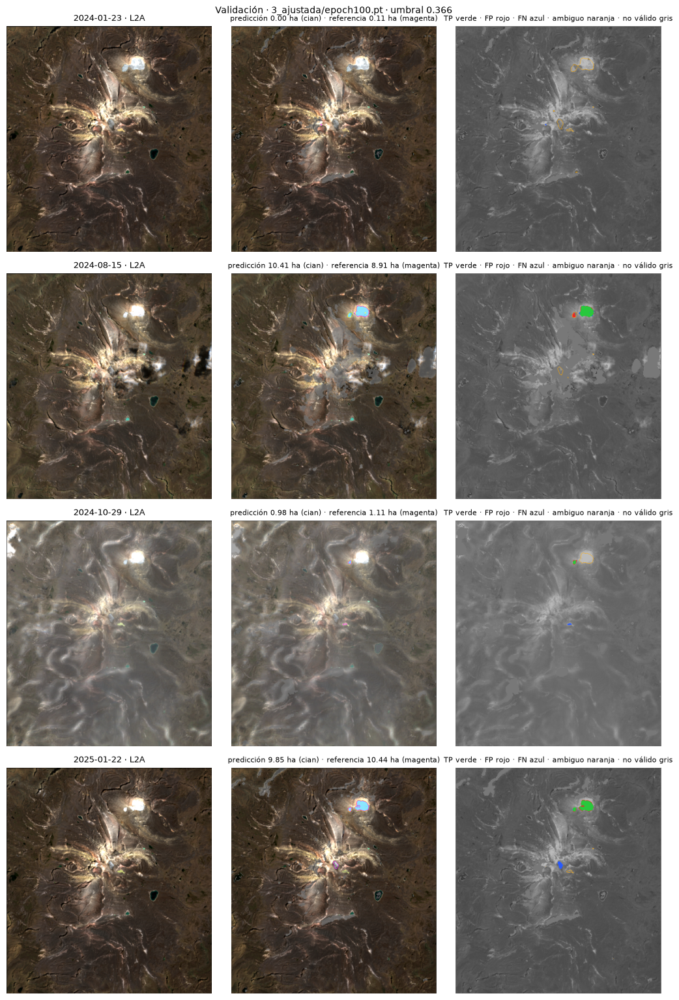

,tramo,parches,recuperados,recall_de_parches
0,5–9 px,0,0,NaN
1,10–24 px,1,0,0.0000
2,25–99 px,3,2,0.6667
3,≥ 100 px,3,2,0.6667


In [8]:
res_val = {s: flujo.metricas_split(el_val, UMBRAL, s) for s in flujo.SOPORTES
           if all(flujo.soporte_valido(x, s) is not None for x in el_val)}
COLUMNAS = ["precision", "recall", "f1", "iou", "exactitud", "auc", "mae_ha", "sesgo_ha", "tp", "fp", "fn", "tn"]
display(pd.DataFrame({s: {c: r["agregado"][c] for c in COLUMNAS} for s, r in res_val.items()}).T)
cuaderno.figura_predicciones(el_val, UMBRAL, REPORTES / "fig_validacion_predicciones.png",
                             f"Validación · {SELECCION['checkpoint']} · umbral {UMBRAL:.3f}", SOPORTE); plt.show()
tabla_parches_val = pd.DataFrame(cuaderno.recall_por_tamano(el_val, UMBRAL))
display(tabla_parches_val)
cuaderno.guardar_csv(res_val[SOPORTE]["por_escena"], REPORTES / "metricas_val_por_escena.csv");

## 6 · Prueba temporal (una sola vez)

La configuración congelada se aplica **una vez** a las escenas de test (fechas posteriores a todo el entrenamiento
y la validación, mismo nevado: mide transferencia entre fechas del lugar). Clasificación binaria por píxel:
precisión = TP/(TP+FP), recall = TP/(TP+FN), F1 = 2TP/(2TP+FP+FN), IoU = TP/(TP+FP+FN). La **ROC** enfrenta FPR y
TPR al recorrer el umbral sobre la puntuación previa al umbral operativo; el **AUC** es el área bajo esa curva.

In [9]:
el_test = flujo.inferir_split(cfg, aud, modelo, "test", protocolo=protocolo, proposito="prueba temporal (unica)")
res_test = {s: flujo.metricas_split(el_test, UMBRAL, s) for s in flujo.SOPORTES
            if all(flujo.soporte_valido(x, s) is not None for x in el_test)}
tabla_test = pd.DataFrame({s: {c: r["agregado"][c] for c in COLUMNAS} for s, r in res_test.items()}).T
display(tabla_test)
por_escena = pd.DataFrame(res_test[SOPORTE]["por_escena"])
columnas_escena = ["mes", "perfil", "referencia", "precision", "recall", "f1", "iou", "auc", "area_ref_ha",
                   "area_pred_ha", "error_ha", "instancias_propuestas", "tope_alcanzado", "nd"]
display(por_escena[[c for c in columnas_escena if c in por_escena]])
for s, r in res_test.items():
    cuaderno.guardar_csv(r["por_escena"], REPORTES / f"metricas_test_por_escena_{s}.csv")
tabla_test.to_csv(REPORTES / "metricas_test_agregadas.csv", encoding="utf-8-sig")
print("Referencia:", ", ".join(identidad["origen_referencia"]), "· revisión humana:", identidad["revision_humana"])
print("Protocolo:", json.dumps({k: v for k, v in protocolo.resumen().items() if k != "eventos"}, ensure_ascii=False))

,precision,recall,f1,iou,exactitud,auc,mae_ha,sesgo_ha,tp,fp,fn,tn
observable,0.8885,0.3896,0.5417,0.3715,0.9982,0.9080,5.0317,-4.9383,2056.0000,258.0000,3221.0000,1878986.0000
imagen,0.8877,0.3896,0.5416,0.3713,0.9982,0.9080,5.0283,-4.9350,2056.0000,260.0000,3221.0000,1949923.0000
observable_sin_ambiguos,0.8897,0.3896,0.5419,0.3717,0.9982,0.9080,5.0367,-4.9433,2056.0000,255.0000,3221.0000,1876777.0000


,mes,perfil,referencia,precision,recall,f1,iou,auc,area_ref_ha,area_pred_ha,error_ha,instancias_propuestas,tope_alcanzado,nd
0,2025-07,L2A,automatico_ndsi,NaN,0.0000,0.0000,0.0000,0.8798,4.3900,0.0000,-4.3900,59,False,precision: sin píxeles predichos como nieve (T...
1,2025-12,L2A,automatico_ndsi,0.8307,0.1200,0.2097,0.1171,0.8436,21.6700,3.1300,-18.5400,93,False,
2,2026-03,L2A,automatico_ndsi,0.8513,0.8513,0.8513,0.7412,0.9293,7.8700,7.8700,0.0000,16,False,
3,2026-05,L2A,automatico_ndsi,0.9159,0.9527,0.9339,0.8760,0.9834,6.9700,7.2500,0.2800,8,False,
4,2026-07,L2A,automatico_ndsi,NaN,0.0000,0.0000,0.0000,0.9995,6.0100,0.0000,-6.0100,19,False,precision: sin píxeles predichos como nieve (T...
5,2026-08,L2A,automatico_ndsi,0.9448,0.7884,0.8595,0.7537,0.9530,5.8600,4.8900,-0.9700,9,False,


Referencia: automatico_ndsi · revisión humana: False
Protocolo: {"configuracion_congelada": {"split": "val", "soporte": "observable", "checkpoint": "3_ajustada/epoch100.pt", "imgsz": 1024, "umbral": 0.36628111720085144, "umbral_f1": 0.37128111720085144, "margen_numerico": 0.0050000000000000044, "f1_val": 0.8662481892805408, "empates_f1": 1, "criterio": "checkpoint y resolución por mayor IoU de cobertura en validación (desempate: menor MAE de área); umbral operativo por máximo F1 en validación (empates → umbral mayor), menos un margen numérico que no cambia la máscara de validación", "candidatos_checkpoint": 19, "iou_val_min": 0.008367053662595016, "iou_val_max": 0.7640545144804088}, "evaluaciones_test": 1, "test_intervino_en_seleccion": false}


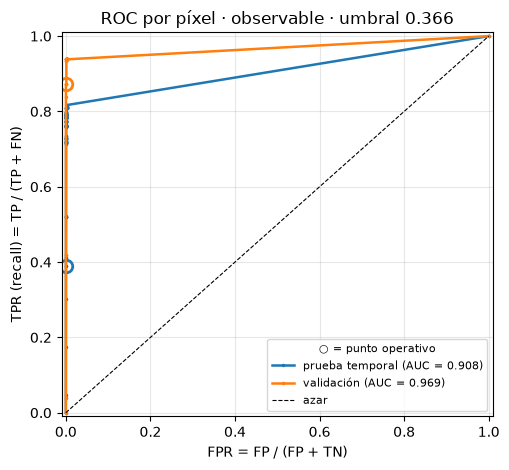

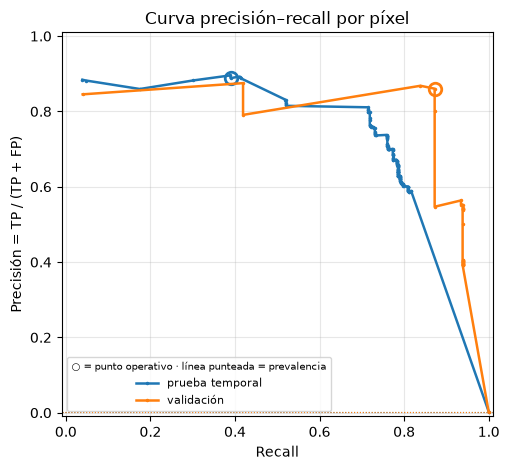

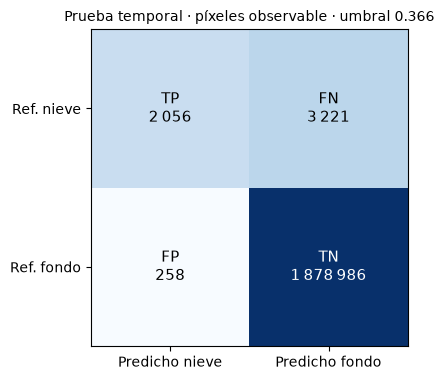

AUC prueba: 0.9079913886377381 · soportes: 5277 px de nieve, 1879244 px de fondo


In [10]:
m_test, m_val = res_test[SOPORTE]["agregado"], res_val[SOPORTE]["agregado"]
curvas = {"prueba temporal": {"roc": res_test[SOPORTE]["roc"], "pr": res_test[SOPORTE]["pr"],
                              "punto": cuaderno.punto_operativo(m_test)},
          "validación": {"roc": res_val[SOPORTE]["roc"], "pr": res_val[SOPORTE]["pr"],
                         "punto": cuaderno.punto_operativo(m_val)}}
cuaderno.figura_roc(curvas, REPORTES / "fig_roc.png", f"ROC por píxel · {SOPORTE} · umbral {UMBRAL:.3f}"); plt.show()
cuaderno.figura_roc({"prueba temporal": curvas["prueba temporal"]}, REPORTES / "roc_test.png", "ROC · prueba temporal")
plt.close()
cuaderno.figura_roc({"validación": curvas["validación"]}, REPORTES / "roc_val.png", "ROC · validación"); plt.close()
cuaderno.figura_pr({"prueba temporal": {"pr": res_test[SOPORTE]["pr"], "punto": (m_test["recall"], m_test["precision"])},
                    "validación": {"pr": res_val[SOPORTE]["pr"], "punto": (m_val["recall"], m_val["precision"])}},
                   REPORTES / "fig_pr.png"); plt.show()
cuaderno.figura_matriz(m_test, REPORTES / "fig_matriz_test.png",
                       f"Prueba temporal · píxeles {SOPORTE} · umbral {UMBRAL:.3f}"); plt.show()
roc = res_test[SOPORTE]["roc"]
if roc["definida"]:
    pd.DataFrame({"fpr": roc["fpr"], "tpr": roc["tpr"], "umbral": roc["umbrales"]}).to_csv(
        REPORTES / "roc_test_puntos.csv", index=False)
print(f"AUC prueba: {roc['auc']} · soportes: {roc['positivos']} px de nieve, {roc['negativos']} px de fondo")

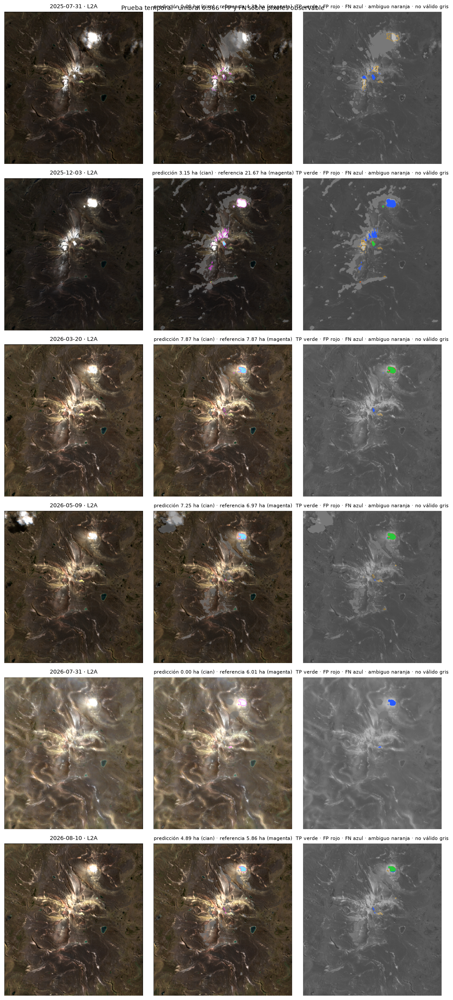

,tramo,parches,recuperados,recall_de_parches
0,5–9 px,15,1,0.0667
1,10–24 px,10,0,0.0000
2,25–99 px,6,1,0.1667
3,≥ 100 px,10,4,0.4000


,precision,recall,f1,iou,exactitud,auc,mae_ha,sesgo_ha
YOLO · observable,0.8885,0.3896,0.5417,0.3715,0.9982,0.9080,5.0317,-4.9383
YOLO · observable_sin_ambiguos,0.8897,0.3896,0.5419,0.3717,0.9982,0.9080,5.0367,-4.9433
NDSI ≥ 0.4 · observable (circular),0.7031,0.9973,0.8248,0.7018,0.9988,0.9996,3.6800,3.6800
NDSI ≥ 0.4 · observable_sin_ambiguos (circular),0.9865,0.9973,0.9919,0.9839,1.0000,1.0000,0.0967,0.0967


Ultralytics 8.4.216  Python-3.11.15 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)


YOLO26n-seg summary (fused): 137 layers, 2,703,783 parameters, 0 gradients, 9.1 GFLOPs


val: Fast image access  (ping: 0.2±0.0 ms, read: 590.7±173.1 MB/s, size: 440.2 KB)


val: Scanning C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS MAESTRÍA\M-S2-VC Proyecto imagenes satelitales YOLO\santa_isabel_yolo\data\datasets\v0003\rgb\labels\test.cache... 6 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 6/6  0.0s

... (10 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 19.8it/s 0.2s

                   all          4          7      0.568      0.857      0.701       0.45      0.779      0.571      0.696      0.364


Speed: 1.3ms preprocess, 26.8ms inference, 0.0ms loss, 3.5ms postprocess per image


,split,imgsz,caja_map50,caja_map50_95,mascara_map50,mascara_map50_95
0,val,1024,0.7010,0.4505,0.6963,0.3635
1,test,1024,0.2526,0.1392,0.2303,0.1117


In [11]:
cuaderno.figura_predicciones(el_test, UMBRAL, REPORTES / "fig_test_predicciones.png",
                             f"Prueba temporal · umbral {UMBRAL:.3f} · FP y FN sobre píxeles {SOPORTE}", SOPORTE)
plt.show()
tabla_parches = pd.DataFrame(cuaderno.recall_por_tamano(el_test, UMBRAL))
display(tabla_parches)
tabla_parches.to_csv(REPORTES / "recall_parches_test.csv", index=False, encoding="utf-8-sig")
ndsi = {s: flujo.comparador_ndsi(el_test, s) for s in res_test if s != "imagen"} if SOPORTE == "observable" else {}
if ndsi:
    comp = pd.DataFrame({f"YOLO · {s}": {c: res_test[s]["agregado"][c] for c in COLUMNAS[:8]} for s in ndsi} |
                        {f"NDSI ≥ {el_test[0]['umbral_ndsi']} · {s} (circular)":
                         {c: r["agregado"][c] for c in COLUMNAS[:8]} for s, r in ndsi.items()}).T
    display(comp)
    comp.to_csv(REPORTES / "comparador_ndsi_test.csv", encoding="utf-8-sig")
map_test = ent.validar_instancias(cfg, PESOS, yamls[VARIANTE], "test", CORRIDA, "val_test", imgsz=IMGSZ)
map_val = ent.validar_instancias(cfg, PESOS, yamls[VARIANTE], "val", CORRIDA, "val_val", imgsz=IMGSZ)
display(pd.DataFrame([map_val, map_test]))

## 7 · Exportación, paquete inmutable e inferencia de ida y vuelta

Se exporta a ONNX para el servicio en CPU (misma rama con NMS que usa la predicción de referencia), se publica el
paquete con contrato, métricas y hashes, se copian dos escenas reales con su máscara de calidad y se reabre todo con
**el mismo cargador que usa Streamlit**: en este proceso (GPU) y en un proceso limpio en CPU con ambos backends.

In [12]:
import onnxruntime, torch, ultralytics
onnx_info = ent.exportar_onnx(cfg, PESOS, IMGSZ, CORRIDA / "export" / "best.onnx")
versiones = {"python": gpu["python"], "torch": gpu["torch"], "torchvision": gpu["torchvision"],
             "ultralytics": gpu["ultralytics"], "cuda": gpu["cuda_compilada"], "numpy": np.__version__,
             "onnx": onnx_info["onnx"], "onnxruntime": onnx_info["onnxruntime"], "so": gpu["so"], "gpu": gpu["gpu"]}
ID = f"si-{VARIANTE}-yolo26n-{RUN_ID}"
registro_elegido = reg_aj if "3_ajustada" in SELECCION["checkpoint"] else reg_ini

def agregados(resultados, instancias):
    salida = {s: cuaderno.solo_escalares(r["agregado"]) | {"nd": r["agregado"]["nd"]} for s, r in resultados.items()}
    salida["instancias"] = instancias
    return salida

metricas = {
    "run_id": RUN_ID, "paquete": ID, "dataset": identidad, "seleccion": SELECCION,
    "referencia": {"origen": identidad["origen_referencia"], "revision_humana": identidad["revision_humana"],
                   "soporte_principal": flujo.SOPORTES[SOPORTE]},
    "val": agregados(res_val, map_val), "test": agregados(res_test, map_test),
    "test_por_escena": res_test[SOPORTE]["por_escena"],
    "recall_parches_test": tabla_parches.to_dict("records"),
    "comparador_ndsi_test": {s: cuaderno.solo_escalares(r["agregado"]) for s, r in ndsi.items()},
    "protocolo": protocolo.resumen(),
    "entrenamiento": {"integracion": reg_int, "inicial": reg_ini, "ajustada": reg_aj},
    "bitacora": {"probado con fixture": "pytest (hitos A–D)", "entrenado en RTX": f"sí ({gpu['gpu']})",
                 "evaluado con datos reales": f"sí ({aud.version}, pseudoetiquetas NDSI)",
                 "verificado en Render": "pendiente (sin acceso a una cuenta)"}}
contrato = cuaderno.contrato_paquete(ID, VARIANTE, cfg, aud, SELECCION, registro_elegido, versiones, onnx_info)
PAQUETE = paquete.publicar_paquete(MODELOS, contrato, {
    "pesos/best.pt": PESOS, "pesos/best.onnx": onnx_info["archivo"],
    "metricas.json": json.dumps(cuaderno._limpio(metricas), ensure_ascii=False, indent=1).encode("utf-8"),
    "roc_test.png": REPORTES / "roc_test.png", "roc_val.png": REPORTES / "roc_val.png",
    "metricas_test_por_escena.csv": REPORTES / f"metricas_test_por_escena_{SOPORTE}.csv"}, activar=True)
cuaderno.guardar_json(metricas, REPORTES / "metricas.json")
print("Paquete publicado:", PAQUETE)
print((PAQUETE / "SHA256SUMS").read_text())

Ultralytics 8.4.216  Python-3.11.15 torch-2.15.0+cu132 CPU (AMD Ryzen 5 5600H with Radeon Graphics)


YOLO26n-seg summary (fused): 137 layers, 2,703,783 parameters, 0 gradients, 23.9 GFLOPs



PyTorch: starting from 'C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS MAESTRÍA\M-S2-VC Proyecto imagenes satelitales YOLO\santa_isabel_yolo\runs\rgb_v0003_20261122_2200\candidatos\3_ajustada__epoch100.pt' with input shape (1, 3, 1024, 1024) BCHW and output shape(s) ((1, 300, 38), (1, 32, 256, 256)) (6.4 MB)



ONNX: starting export with onnx 1.23.2 opset 18...


ONNX: slimming with onnxslim 0.1.99...


ONNX: export success  4.7s, saved as 'C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS MAESTRÍA\M-S2-VC Proyecto imagenes satelitales YOLO\santa_isabel_yolo\runs\rgb_v0003_20261122_2200\candidatos\3_ajustada__epoch100.onnx' (10.9 MB)



Export complete (5.2s)
Results saved to C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS MAESTRÍA\M-S2-VC Proyecto imagenes satelitales YOLO\santa_isabel_yolo\runs\rgb_v0003_20261122_2200\candidatos\3_ajustada__epoch100.onnx
Predict:         yolo predict task=segment model=C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS MAESTRÍA\M-S2-VC Proyecto imagenes satelitales YOLO\santa_isabel_yolo\runs\rgb_v0003_20261122_2200\candidatos\3_ajustada__epoch100.onnx imgsz=1024 
Validate:        yolo val task=segment model=C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS MAESTRÍA\M-S2-VC Proyecto imagenes satelitales YOLO\santa_isabel_yolo\runs\rgb_v0003_20261122_2200\candidatos\3_ajustada__epoch100.onnx imgsz=1024 data=C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS MAESTRÍA\M-S2-VC Proyecto imagenes satelitales YOLO\santa_isabel_yolo\runs\rgb_v0003_20261122_2200\data_yaml\v0003_rgb.yaml 
Visualize:       https://netron.app


Paquete publicado: C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS MAESTRÍA\M-S2-VC Proyecto imagenes satelitales YOLO\santa_isabel_yolo\models\si-rgb-yolo26n-rgb_v0003_20261122_2200
5ddfcdcff693dd7dc9e351aeb6367468eb29e0581a0d8dcb7c3b5aa9ebc20a61  metricas.json
8f784bcbcf3106934c8e2a6695e5f2c7e2b6119248d5b9e2105fc4bbd82dbf5e  metricas_test_por_escena.csv
2e8733fabf4e54cdc1cf89734dbbb8998457133fe7ecd18fa48df48718305524  modelo.json
f133a5faf11eac602dfb488ad2a2e091268215d65cd26860ed4dc5b1c097ae17  pesos/best.onnx
65d6984adf4028f2edbad71a022492587050549c4b4ee4fa3da8c92a1c78365b  pesos/best.pt
87f64133a6313d2f919cfd87c3f861a18bd984a4e577c04059792bde117f280a  roc_test.png
349c55fe70444cd37b61b75ea85d445c5a8d30c97751dadf5c47d4b36ca52e11  roc_val.png



**Dos escenas reales para la demostración.** Mismo mes en años distintos, ninguna de entrenamiento, con su máscara
de calidad. Se copian de la caché del productor (solo lectura) con fuente y crédito; es lo único que la app necesita
empaquetar para Render.

Par elegido (mes inicial, mes final): ['2024-08', '2026-08']


20240815_T18NVL_20240815T152651_20240815T152653: val · 2024-08-15 · 545×598 · observable 93.6 % · 462 kB
20260810_T18NVL_20260810T152649_20260810T152745: test · 2026-08-10 · 545×598 · observable 97.3 % · 450 kB


,fecha,estado,area_nieve_ha,area_observable_ha,area_aoi_ha,pct_nieve_aoi,pct_observable_aoi,qa
0,2024-08-15,cuantitativa,10.0200,3049.6300,3241.7100,0.3091,94.0747,"calidad.tif = 2 (SCL clases útiles 4,5,6,11) y..."
1,2026-08-10,cuantitativa,4.8900,3170.5900,3241.7100,0.1508,97.8061,"calidad.tif = 2 (SCL clases útiles 4,5,6,11) y..."


,comparación de dos fechas
estado,ok
fecha_inicial_utc,2024-08-15T15:31:49Z
fecha_final_utc,2026-08-10T15:31:46Z
clave_inicial,20240815_T18NVL_20240815T152651_20240815T152653
clave_final,20260810_T18NVL_20260810T152649_20260810T152745
fechas_invertidas_en_la_carga,False
area_inicial_comparable_ha,9.7800
area_final_comparable_ha,4.8900
persistencia_ha,4.8700
perdida_bruta_ha,4.9100


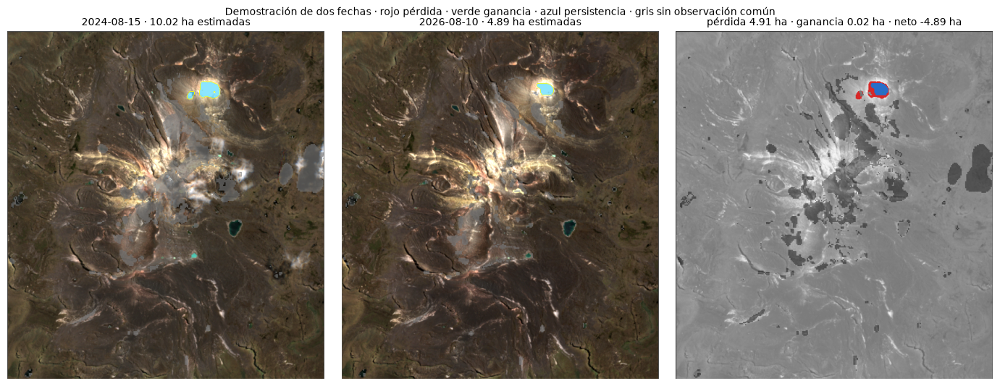

In [13]:
sys.path.insert(0, str(RAIZ / "tools"))
import preparar_ejemplos
PAR = cuaderno.elegir_par_demo(tabla_ref)
print("Par elegido (mes inicial, mes final):", PAR)
claves = preparar_ejemplos.preparar(PAR, EJEMPLOS) if PAR else []

servicio = paquete.cargar_paquete(PAQUETE, dispositivo=0, backend="ultralytics")   # mismo cargador que la app
analisis = [flujo.analizar_escena(leer_escena(EJEMPLOS / c), servicio, cfg) for c in claves]
cambio = flujo.comparar_fechas(*analisis, cfg) if len(analisis) == 2 else None
filas_demo = [{"escena": a.escena.clave, "fecha": f"{a.escena.fecha:%Y-%m-%d}", **a.medicion.como_fila()}
              for a in analisis]
display(pd.DataFrame(filas_demo)[["fecha", "estado", "area_nieve_ha", "area_observable_ha", "area_aoi_ha",
                                  "pct_nieve_aoi", "pct_observable_aoi", "qa"]])
if cambio is not None:
    display(pd.Series(cambio.como_fila(), name="comparación de dos fechas").to_frame())
    fig, ejes = plt.subplots(1, 3, figsize=(14, 5.4))
    for eje, a in zip(ejes, analisis):
        eje.imshow(visual.superponer(visual.realzar(a.escena.rgb8), a.prediccion.mascara, a.escena.observable))
        eje.set_title(f"{a.escena.fecha:%Y-%m-%d} · {a.medicion.area_nieve_ha:.2f} ha estimadas", fontsize=10)
    ejes[2].imshow(visual.mapa_cambio_rgb(cambio.mapa, visual.realzar(analisis[-1].escena.rgb8)))
    ejes[2].set_title(f"pérdida {cambio.perdida_ha:.2f} ha · ganancia {cambio.ganancia_ha:.2f} ha · neto "
                      f"{cambio.cambio_neto_ha:+.2f} ha", fontsize=10)
    for eje in ejes:
        eje.axis("off")
    fig.suptitle("Demostración de dos fechas · rojo pérdida · verde ganancia · azul persistencia · gris sin "
                 "observación común", fontsize=10)
    fig.tight_layout(); fig.savefig(REPORTES / "fig_demo_dos_fechas.png", dpi=110); plt.show()
    cuaderno.guardar_csv([cambio.como_fila()], REPORTES / "demo_comparacion.csv")
cuaderno.guardar_csv(filas_demo, REPORTES / "demo_escenas.csv");

**Proceso limpio en CPU.** Un intérprete nuevo reabre el paquete (verifica hashes y contrato), analiza las dos
escenas con ONNX Runtime y con PyTorch en CPU y las compara. Debe dar las mismas áreas que la GPU.

In [14]:
verificacion = {"backends": {}}
for backend in ("onnx", "ultralytics"):          # un proceso limpio por backend: tiempos y memoria no se mezclan
    salida = subprocess.run([sys.executable, str(RAIZ / "tools" / "verificar_paquete.py"), str(PAQUETE),
                             "--ejemplos", str(EJEMPLOS), "--backends", backend],
                            capture_output=True, text=True, encoding="utf-8")
    if salida.returncode != 0:
        raise RuntimeError(f"La verificación en proceso limpio ({backend}) falló:\n" + salida.stderr[-3000:])
    datos = json.loads(salida.stdout[salida.stdout.index("{"):])
    verificacion["backends"].update(datos["backends"])
    verificacion.update({k: v for k, v in datos.items() if k != "backends"})
    print(f"{backend}: torch cargado en el proceso = {datos['backends'][backend]['torch_cargado']} · memoria pico "
          f"{datos['backends'][backend]['memoria_pico_mib']} MiB")
filas = [{"backend": "ultralytics · GPU (este cuaderno)", "clave": a.escena.clave,
          "area_nieve_ha": a.medicion.area_nieve_ha, "pixeles_nieve": a.medicion.pixeles_nieve,
          "parches": a.prediccion.instancias_operativas, "segundos_inferencia": round(a.prediccion.segundos, 3)}
         for a in analisis]
for nombre, datos in verificacion["backends"].items():
    filas += [{"backend": f"{nombre} · CPU (proceso limpio)", **{k: x[k] for k in ("clave", "area_nieve_ha",
               "pixeles_nieve", "parches", "segundos_inferencia")}, "memoria_pico_mib": datos["memoria_pico_mib"],
               "carga_modelo_s": datos["segundos_carga_modelo"]} for x in datos["escenas"]]
tabla_backends = pd.DataFrame(filas)
display(tabla_backends)
tabla_backends.to_csv(REPORTES / "verificacion_backends.csv", index=False, encoding="utf-8-sig")
cuaderno.guardar_json(verificacion, REPORTES / "verificacion_cpu.json")
ref = {a.escena.clave: a.medicion.pixeles_nieve for a in analisis}
dif = {f"{n}/{x['clave'][:8]}": x["pixeles_nieve"] - ref[x["clave"]] for n, d in verificacion["backends"].items()
       for x in d["escenas"]}
print("Diferencia en píxeles de nieve frente a la GPU:", dif)
assert all(abs(v) <= max(5, 0.01 * max(ref.values())) for v in dif.values()), "los backends no son equivalentes"
print("\nCorrida", RUN_ID, "terminada. Paquete:", PAQUETE, "· evidencias:", REPORTES)

onnx: torch cargado en el proceso = False · memoria pico 453.7 MiB


ultralytics: torch cargado en el proceso = True · memoria pico 865.9 MiB


,backend,clave,area_nieve_ha,pixeles_nieve,parches,segundos_inferencia,memoria_pico_mib,carga_modelo_s
0,ultralytics · GPU (este cuaderno),20240815_T18NVL_20240815T152651_20240815T152653,10.0200,1002,2,0.2690,NaN,NaN
1,ultralytics · GPU (este cuaderno),20260810_T18NVL_20260810T152649_20260810T152745,4.8900,489,1,0.0600,NaN,NaN
2,onnx · CPU (proceso limpio),20240815_T18NVL_20240815T152651_20240815T152653,10.0200,1002,2,0.3340,453.7000,0.3000
3,onnx · CPU (proceso limpio),20260810_T18NVL_20260810T152649_20260810T152745,4.8900,489,1,0.2600,453.7000,0.3000
4,ultralytics · CPU (proceso limpio),20240815_T18NVL_20240815T152651_20240815T152653,10.0200,1002,2,3.6720,865.9000,4.2600
5,ultralytics · CPU (proceso limpio),20260810_T18NVL_20260810T152649_20260810T152745,4.8900,489,1,0.2190,865.9000,4.2600


Diferencia en píxeles de nieve frente a la GPU: {'onnx/20240815': 0, 'onnx/20260810': 0, 'ultralytics/20240815': 0, 'ultralytics/20260810': 0}

Corrida rgb_v0003_20261122_2200 terminada. Paquete: C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS MAESTRÍA\M-S2-VC Proyecto imagenes satelitales YOLO\santa_isabel_yolo\models\si-rgb-yolo26n-rgb_v0003_20261122_2200 · evidencias: C:\Users\ing_c\OneDrive\Documentos\DESARROLLOS MAESTRÍA\M-S2-VC Proyecto imagenes satelitales YOLO\santa_isabel_yolo\reports\rgb_v0003_20261122_2200
